# XRR thickness fit: 

**Step 1:** Read the data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, differential_evolution

df = pd.read_csv("979D_XRR.csv")          # columns: x (= q in Å^-1), y (= reflectivity, normalized), error
q_all, R_all = df["x"].to_numpy(), df["y"].to_numpy()
print(df.shape)
df.head()

(566, 3)


,x,y,error
0,0.014242,0.369966,0.0
1,0.014954,0.388488,0.0
2,0.015666,0.406306,0.0
3,0.016378,0.425887,0.0
4,0.017090,0.440689,0.0


**Step 2:** Plot the data.

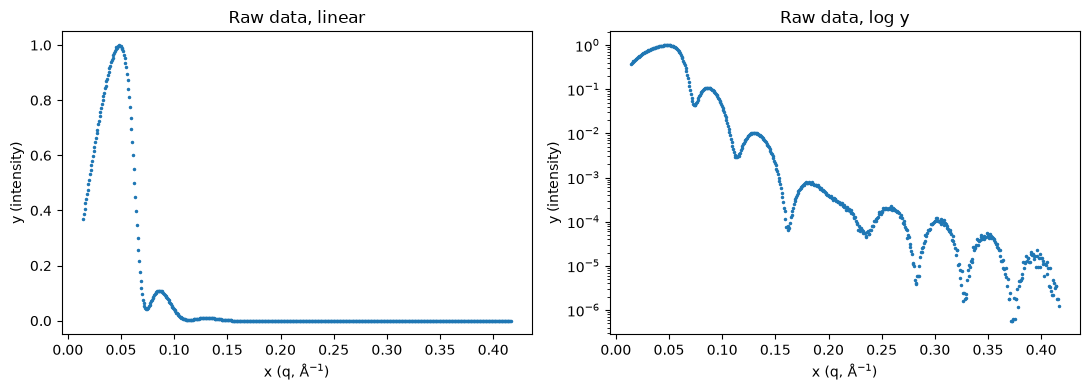

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(df["x"], df["y"], ".", ms=3)
ax1.set(xlabel="x (q, Å$^{-1}$)", ylabel="y (intensity)", title="Raw data, linear")

ax2.semilogy(df["x"], df["y"], ".", ms=3)
ax2.set(xlabel="x (q, Å$^{-1}$)", ylabel="y (intensity)", title="Raw data, log y")

plt.tight_layout()
plt.show()

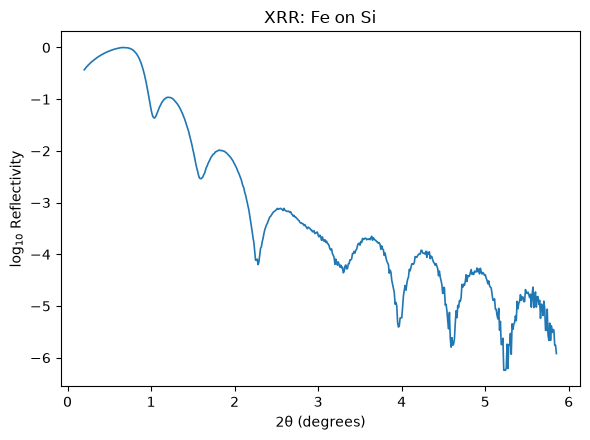

,x,two_theta,y,log_R
0,0.014242,0.200078,0.369966,-0.431838
1,0.014954,0.210082,0.388488,-0.410622
2,0.015666,0.220086,0.406306,-0.391147
3,0.016378,0.230090,0.425887,-0.370706
4,0.017090,0.240094,0.440689,-0.355868


In [4]:
wavelength = 1.5406                     # Å, Cu K-alpha

q = df["x"].to_numpy()
theta = np.arcsin(q * wavelength / (4 * np.pi))   # radians
df["two_theta"] = np.degrees(2 * theta)           # degrees
df["log_R"] = np.log10(df["y"])

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(df["two_theta"], df["log_R"], "-", lw=1.2)
ax.set(xlabel="2θ (degrees)", ylabel="log$_{10}$ Reflectivity",
       title="XRR: Fe on Si")
plt.tight_layout()
plt.show()

df[["x", "two_theta", "y", "log_R"]].head()

**Step 3: Define the sample. Edit this cell.**

- `wavelength`: X-ray wavelength in Å (Cu Kα = 1.5406).
- `materials`: optical constants `(delta, beta)` at that wavelength. **To add a material, add a line.** Values are approximate (Cu Kα): please check them for your material, e.g. on the CXRO site (henke.lbl.gov).
- `stack`: layers from the **top** (air side) down to the substrate. **To add a layer, add a line.** Each number is `[start, min, max, vary]`; use `vary=False` to hold it fixed.
  - `t`: thickness (Å), `sigma`: roughness of the layer's top interface (Å), `dens`: density relative to bulk.
- `substrate`: material and roughness of the Fe/Si interface (the interface above the substrate).

In [5]:
# material: (delta, beta) at Cu K-alpha (approximate; verify for your material)
materials = {
    "Ta":    (4.1e-5, 3.3e-6),
    "Fe":    (2.24e-5, 2.9e-6),
    "Si":    (7.6e-6, 1.75e-7),
    "Ta2O5": (2.2e-5, 1.3e-6),
    "FeOx":  (1.6e-5, 1.4e-6),
}

# top -> bottom.  [start, min, max, vary]
stack = [
    {"material": "Ta2O5", "t": [ 20.0, 0.0,  60.0, True], "sigma": [3.0, 0.0, 12.0, True], "dens": [1.0, 0.7, 1.1, False]},  # Ta surface oxide
    {"material": "Ta",    "t": [ 40.0, 0.0,  80.0, True], "sigma": [3.0, 0.0, 12.0, True], "dens": [1.0, 0.7, 1.1, False]},  # Ta protective layer
    {"material": "Fe",    "t": [100.0, 60.0, 220.0, True], "sigma": [4.0, 0.0, 12.0, True], "dens": [1.0, 0.7, 1.1, False]},  # Fe film
]
substrate = {"material": "Si", "sigma": [3.0, 0.0, 12.0, True]}

scale = [1.0, 0.3, 5.0, True]       # overall intensity scale
bg    = [0.0, 0.0, 1e-6, False]     # constant background

q_min, q_max = 0.0, 0.42            # q-range used in the fit (Å^-1)
global_search = True                # True = global search first (robust, slower), then local refinement 



**Step 4:** The model (Parratt recursion with Névot–Croce roughness). Nothing to edit here.

In [6]:
k0 = 2 * np.pi / wavelength

def parratt(q, media, thickness, sigma):
    """media: [(delta, beta)] vacuum..substrate; thickness: finite layers; sigma: roughness of each interface."""
    kz = q / 2
    kzs = [np.sqrt(kz**2 - 2 * k0**2 * (d - 1j * b) + 0j) for d, b in media]
    r_tot = None
    for j in range(len(media) - 2, -1, -1):
        r = (kzs[j] - kzs[j+1]) / (kzs[j] + kzs[j+1]) * np.exp(-2 * kzs[j] * kzs[j+1] * sigma[j]**2)
        if r_tot is None:
            r_tot = r
        else:
            ph = np.exp(2j * kzs[j+1] * thickness[j])
            r_tot = (r + r_tot * ph) / (1 + r * r_tot * ph)
    return np.abs(r_tot)**2

# Build the flat list of fit parameters from the stack above
specs = {}                                  # name -> [start, min, max, vary]
for i, L in enumerate(stack):
    for key in ("t", "sigma", "dens"):
        specs[f"{L['material']}{i+1}_{key}"] = L[key]
specs["substrate_sigma"] = substrate["sigma"]
specs["scale"], specs["bg"] = scale, bg

names = list(specs)
free = [n for n in names if specs[n][3]]

def pack(vec):
    p = {n: specs[n][0] for n in names}
    p.update(dict(zip(free, vec)))
    return p

def model(p, q):
    media, thick, sig = [(0.0, 0.0)], [], []
    for i, L in enumerate(stack):
        d, b = materials[L["material"]]
        f = p[f"{L['material']}{i+1}_dens"]
        media.append((d * f, b * f))
        thick.append(p[f"{L['material']}{i+1}_t"])
        sig.append(p[f"{L['material']}{i+1}_sigma"])
    media.append(materials[substrate["material"]])
    sig.append(p["substrate_sigma"])
    return p["scale"] * parratt(q, media, thick, sig) + p["bg"]

**Step 5:** Run the fit, then print the thickness of each layer and plot the result.

rms of log10(R) residuals: 0.197

parameter              value   1-sigma
Ta2O51_t               17.34   ± 0.122
Ta2O51_sigma            3.27   ± 0.0901
Ta2O51_dens                1   (fixed)
Ta2_t                  18.64   ± 0.212
Ta2_sigma              5.096   ± 0.155
Ta2_dens                   1   (fixed)
Fe3_t                  100.5   ± 0.168
Fe3_sigma              5.767   ± 0.143
Fe3_dens                   1   (fixed)
substrate_sigma        2.476   ± 0.105
scale                 0.9646   ± 0.031
bg                         0   (fixed)

Thickness results
  Ta2O5     1.73 nm  (± 0.01)
  Ta        1.86 nm  (± 0.02)
  Fe       10.05 nm  (± 0.02)
  total    13.65 nm


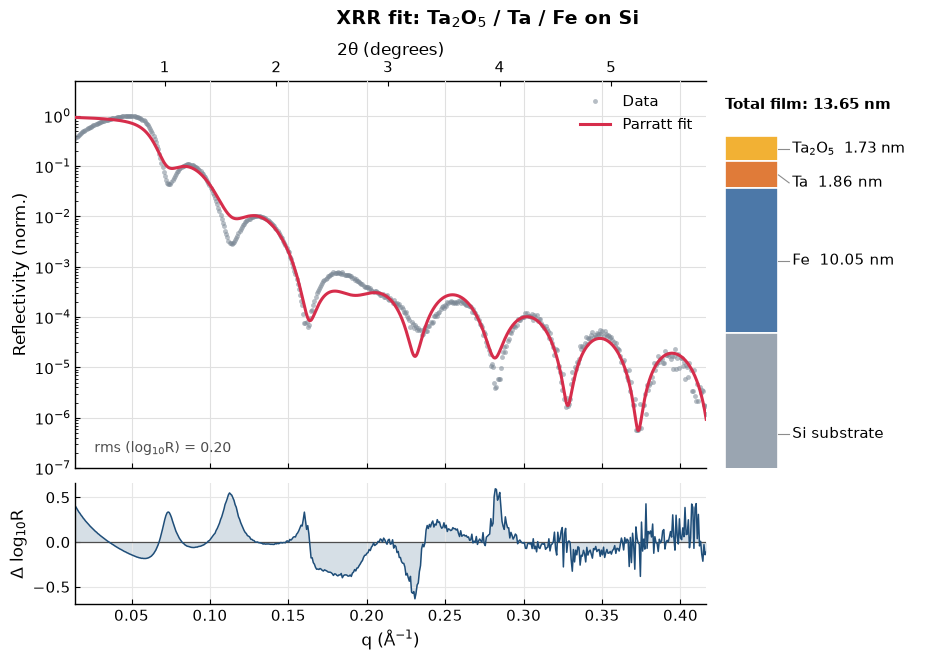

In [7]:
mask = (q_all >= q_min) & (q_all <= q_max)
q_fit, R_fit = q_all[mask], R_all[mask]

def residuals(vec):
    return np.log10(np.maximum(model(pack(vec), q_fit), 1e-12)) - np.log10(R_fit)

x0 = [specs[n][0] for n in free]
lo = [specs[n][1] for n in free]
hi = [specs[n][2] for n in free]

if global_search:
    de = differential_evolution(lambda v: np.sum(residuals(v)**2), list(zip(lo, hi)),
                                seed=0, maxiter=300, popsize=20, polish=False)
    x0 = de.x
res = least_squares(residuals, x0, bounds=(lo, hi))
best = pack(res.x)

dof = max(len(q_fit) - len(free), 1)
cov = np.linalg.pinv(res.jac.T @ res.jac) * np.sum(res.fun**2) / dof
err = dict(zip(free, np.sqrt(np.diag(cov))))

print(f"rms of log10(R) residuals: {np.sqrt(np.mean(res.fun**2)):.3f}\n")
print(f"{'parameter':18s}{'value':>10s}   1-sigma")
for n in names:
    e = f"± {err[n]:.3g}" if n in err else "(fixed)"
    at_bound = n in free and (np.isclose(best[n], specs[n][1]) or np.isclose(best[n], specs[n][2]))
    print(f"{n:18s}{best[n]:10.4g}   {e}{'   <-- at a bound' if at_bound else ''}")

print("\nThickness results")
total = 0.0
for i, L in enumerate(stack):
    t = best[f"{L['material']}{i+1}_t"]
    total += t
    e = err.get(f"{L['material']}{i+1}_t")
    print(f"  {L['material']:6s} {t/10:7.2f} nm" + (f"  (± {e/10:.2f})" if e else ""))
print(f"  total  {total/10:7.2f} nm")

# ---------- final plot ----------
import re
from matplotlib.patches import Rectangle
from matplotlib.ticker import LogLocator, NullFormatter

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.linewidth": 1.0, "xtick.direction": "in", "ytick.direction": "in"})
c_data, c_fit, c_res = "#7a8794", "#d62d4b", "#1f4e79"
layer_colors = ["#f2b134", "#e07b39", "#4c78a8", "#2f9e8f", "#8e6bbf"]   # one colour per layer (top to bottom)
c_sub = "#9aa5b1"
pretty = lambda m: re.sub(r"(\d+)", r"$_{\1}$", m)                       # Ta2O5 -> Ta$_2$O$_5$

q_plot = np.linspace(q_all.min(), q_all.max(), 2000)
fig = plt.figure(figsize=(11, 6.8))
gs = fig.add_gridspec(2, 2, width_ratios=[4, 1.3], height_ratios=[3.2, 1], hspace=0.06, wspace=0.04)
ax  = fig.add_subplot(gs[0, 0])
axr = fig.add_subplot(gs[1, 0], sharex=ax)
axs = fig.add_subplot(gs[0, 1])

# main panel: data and fit
ax.semilogy(q_all, R_all, "o", ms=3.5, mfc=c_data, mec="none", alpha=0.55, label="Data", zorder=2)
ax.semilogy(q_plot, model(best, q_plot), "-", color=c_fit, lw=2.2, label="Parratt fit", zorder=3)
ax.set_ylim(1e-7, 5)
ax.set_ylabel("Reflectivity (norm.)", fontsize=12)
ax.yaxis.set_major_locator(LogLocator(base=10, numticks=12))
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1, numticks=12))
ax.yaxis.set_minor_formatter(NullFormatter())
ax.grid(True, which="major", color="0.88", lw=0.8)
ax.legend(frameon=False, loc="upper right", fontsize=11)
ax.text(0.03, 0.04, f"rms (log$_{{10}}$R) = {np.sqrt(np.mean(res.fun**2)):.2f}", transform=ax.transAxes,
        fontsize=10, color="0.3")
ax.tick_params(labelbottom=False)

# secondary x axis: 2theta (degrees)
sec = ax.secondary_xaxis("top",
        functions=(lambda x: np.degrees(2 * np.arcsin(np.clip(x * wavelength / (4 * np.pi), -1, 1))),
                   lambda t: 4 * np.pi * np.sin(np.radians(t) / 2) / wavelength))
sec.set_xlabel("2θ (degrees)", fontsize=12)
sec.spines["top"].set_visible(True)

# residual panel
axr.axhline(0, color="0.3", lw=0.9)
axr.fill_between(q_fit, res.fun, 0, color=c_res, alpha=0.18, lw=0)
axr.plot(q_fit, res.fun, "-", color=c_res, lw=1.1)
axr.set_xlabel("q (Å$^{-1}$)", fontsize=12)
axr.set_ylabel("Δ log$_{10}$R", fontsize=12)
axr.grid(True, color="0.9", lw=0.8)
axr.set_xlim(q_all.min(), q_all.max())

# side panel: sample sketch with thicknesses (top layer at the top)
sub_h, bar_w = 14.0, 0.5
t_nm = [best[f"{L['material']}{i+1}_t"] / 10 for i, L in enumerate(stack)]
H = sub_h + sum(t_nm)
y = H
bars = []                                                    # (label, colour, y_bottom, height)
for i, L in enumerate(stack):
    y -= t_nm[i]
    bars.append((f"{pretty(L['material'])}  {t_nm[i]:.2f} nm", layer_colors[i % len(layer_colors)], y, t_nm[i]))
bars.append((f"{pretty(substrate['material'])} substrate", c_sub, 0.0, sub_h))
for lab, col, yb, h in bars:
    axs.add_patch(Rectangle((0, yb), bar_w, h, fc=col, ec="white", lw=1.2))
# labels to the right, spread out so thin layers do not overlap
gap = H * 0.085
centers = [yb + h / 2 for _, _, yb, h in bars]
ly = []
for k, c in enumerate(centers):
    ly.append(c if k == 0 else min(c, ly[-1] - gap))
for (lab, col, yb, h), c, l in zip(bars, centers, ly):
    axs.plot([bar_w, bar_w + 0.1], [c, l], color="0.55", lw=0.8)
    axs.text(bar_w + 0.13, l, lab, va="center", ha="left", fontsize=10.5)
axs.text(0, H + H * 0.06, f"Total film: {sum(t_nm):.2f} nm", fontsize=11, fontweight="bold", va="bottom")
axs.set_xlim(-0.02, 1.9); axs.set_ylim(min(ly) - gap, H + H * 0.14); axs.axis("off")

fig.suptitle("XRR fit: " + " / ".join(pretty(L["material"]) for L in stack) + " on " + pretty(substrate["material"]),
             fontsize=14, fontweight="bold", y=0.985)
plt.savefig('XRR_Fe_fit.png', dpi=300, bbox_inches='tight')
plt.show()
